# Customer Churn & Retention — Data Audit and EDA

Reproducible workflow: audit -> cleaning decisions -> cleaned export -> KPIs -> segments -> prioritization -> figures. Run all cells in order; it writes `data/processed/telco_customer_churn_clean.csv` (read by the Streamlit dashboard) and the tables/figures in `outputs/`. Interpreted results are in `docs/10_business_insights.md` and `docs/11_final_report.md`.

**Source file expected:** `data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv` (relative to the project root).

**Important:** the dataset is a customer snapshot. Use descriptive language; do not claim causality, future-period forecasting, or cohort retention from this file alone.

In [1]:
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
# If you opened Jupyter from notebooks/, adjust the root to its parent.
if not (PROJECT_ROOT / "data" / "raw").exists() and (PROJECT_ROOT.parent / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. Download the Kaggle CSV and put it in data/raw/."
    )

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset path: {DATA_PATH}")

Project root: C:\Users\ARII\Documents\proyek data analis\customer_churn_retention_analytics
Dataset path: C:\Users\ARII\Documents\proyek data analis\customer_churn_retention_analytics\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv


## 1. Load the raw CSV and inspect its shape

In [2]:
# Read TotalCharges as text first so blank strings can be audited before conversion.
raw = pd.read_csv(DATA_PATH, dtype={"TotalCharges": "string"})
print("Rows:", len(raw))
print("Columns:", len(raw.columns))
display(raw.head())
print("Column names:", raw.columns.tolist())

Rows: 7043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Column names: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


## 2. Standardize column names and audit data quality

In [3]:
def normalize_column_name(name: str) -> str:
    # First normalize punctuation/spaces, then handle compact camel-case names in this CSV.
    normalized = re.sub(r"[^a-zA-Z0-9]+", "_", name.strip()).strip("_").lower()
    compact_map = {
        "customerid": "customer_id",
        "seniorcitizen": "senior_citizen",
        "phoneservice": "phone_service",
        "multiplelines": "multiple_lines",
        "internetservice": "internet_service",
        "onlinesecurity": "online_security",
        "onlinebackup": "online_backup",
        "deviceprotection": "device_protection",
        "techsupport": "tech_support",
        "streamingtv": "streaming_tv",
        "streamingmovies": "streaming_movies",
        "paperlessbilling": "paperless_billing",
        "paymentmethod": "payment_method",
        "monthlycharges": "monthly_charges",
        "totalcharges": "total_charges",
    }
    return compact_map.get(normalized, normalized)

df = raw.copy()
df.columns = [normalize_column_name(c) for c in df.columns]

# Convert whitespace-only strings to missing values for audit purposes.
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace("", pd.NA)

missing_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
}).sort_values("missing_count", ascending=False)

duplicate_customer_ids = int(df["customer_id"].duplicated().sum()) if "customer_id" in df.columns else None
print("Duplicate customer ID rows:", duplicate_customer_ids)
display(missing_summary)
missing_summary.to_csv(OUTPUT_DIR / "data_quality_missing_summary.csv", index=True)

Duplicate customer ID rows: 0


,dtype,missing_count,missing_pct
total_charges,string,11,0.16
customer_id,string,0,0.00
device_protection,string,0,0.00
monthly_charges,float64,0,0.00
payment_method,string,0,0.00
paperless_billing,string,0,0.00
contract,string,0,0.00
streaming_movies,string,0,0.00
streaming_tv,string,0,0.00
tech_support,string,0,0.00


## 3. Clean types conservatively and record validation checks

In [4]:
# Convert numeric fields. Invalid values become NaN and should be investigated, not silently ignored.
for col in ["tenure", "senior_citizen", "monthly_charges", "total_charges"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Do not silently remove duplicate rows. Keep a documented duplicate audit first.
quality_checks = pd.DataFrame([
    {"check": "row_count", "result": len(df)},
    {"check": "column_count", "result": len(df.columns)},
    {"check": "duplicate_customer_id_rows", "result": duplicate_customer_ids},
    {"check": "blank_or_missing_customer_id", "result": int(df["customer_id"].isna().sum()) if "customer_id" in df.columns else None},
    {"check": "missing_total_charges_after_numeric_conversion", "result": int(df["total_charges"].isna().sum()) if "total_charges" in df.columns else None},
    {"check": "invalid_or_missing_churn_label", "result": int((~df["churn"].isin(["Yes", "No"]) | df["churn"].isna()).sum()) if "churn" in df.columns else None},
])
display(quality_checks)
quality_checks.to_csv(OUTPUT_DIR / "data_quality_checks.csv", index=False)

if "churn" in df.columns:
    print("Observed churn labels:")
    display(df["churn"].value_counts(dropna=False).rename_axis("churn").to_frame("customers"))
    print("Unique customer ID count:", df["customer_id"].nunique(dropna=True))

,check,result
0,row_count,7043
1,column_count,21
2,duplicate_customer_id_rows,0
3,blank_or_missing_customer_id,0
4,missing_total_charges_after_numeric_conversion,11
5,invalid_or_missing_churn_label,0


Observed churn labels:


,customers
churn,
No,5174
Yes,1869


Unique customer ID count: 7043


## 4. Create the analytical population and KPI summary

In [5]:
# Analysis population: valid customer IDs and explicit churn labels only.
# This filtering rule should match the SQL logic for reconcilable counts.
analysis = df.loc[
    df["customer_id"].notna() & df["churn"].isin(["Yes", "No"])
].copy()

# Do not arbitrarily drop duplicate IDs. Stop and inspect if duplicate IDs exist.
if analysis["customer_id"].duplicated().any():
    raise ValueError("Duplicate customer IDs exist in the analysis population. Inspect the audit before continuing.")

analysis["churn_flag"] = analysis["churn"].map({"Yes": 1, "No": 0})
analysis["tenure_band"] = pd.cut(
    analysis["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["00-06 months", "07-12 months", "13-24 months", "25-48 months", "49-72 months"],
    include_lowest=True,
)

churned = analysis[analysis["churn"].eq("Yes")]
retained = analysis[analysis["churn"].eq("No")]
kpi_summary = pd.DataFrame([{
    "valid_customers": len(analysis),
    "churned_customers": len(churned),
    "retained_customers": len(retained),
    "observed_churn_rate_pct": round(100 * analysis["churn_flag"].mean(), 2) if len(analysis) else None,
    "avg_tenure_churned_months": round(churned["tenure"].mean(), 2),
    "avg_tenure_retained_months": round(retained["tenure"].mean(), 2),
    "monthly_charges_churn_group": round(churned["monthly_charges"].sum(min_count=1), 2),
    "avg_monthly_charges_churned": round(churned["monthly_charges"].mean(), 2),
    "avg_monthly_charges_retained": round(retained["monthly_charges"].mean(), 2),
}])
display(kpi_summary)
kpi_summary.to_csv(OUTPUT_DIR / "kpi_summary.csv", index=False)

print("Interpretation note: monthly_charges_churn_group is a descriptive sum for customers labeled as churned, not guaranteed recoverable revenue.")

,valid_customers,churned_customers,retained_customers,observed_churn_rate_pct,avg_tenure_churned_months,avg_tenure_retained_months,monthly_charges_churn_group,avg_monthly_charges_churned,avg_monthly_charges_retained
0,7043,1869,5174,26.54,17.98,37.57,139130.85,74.44,61.27


Interpretation note: monthly_charges_churn_group is a descriptive sum for customers labeled as churned, not guaranteed recoverable revenue.


## 5. Segment churn by category (rate and counts together)

In [6]:
def segment_summary(data: pd.DataFrame, column: str) -> pd.DataFrame:
    result = (
        data.groupby(column, dropna=False, observed=True)
        .agg(
            customers=("customer_id", "nunique"),
            churned_customers=("churn_flag", "sum"),
        )
        .reset_index()
    )
    result["churn_rate_pct"] = (100 * result["churned_customers"] / result["customers"]).round(2)
    return result.sort_values(["churn_rate_pct", "customers"], ascending=[False, False])

segment_columns = [
    "contract", "tenure_band", "payment_method", "internet_service",
    "tech_support", "online_security", "paperless_billing"
]
segment_outputs = {}
for column in segment_columns:
    if column in analysis.columns:
        summary = segment_summary(analysis, column)
        segment_outputs[column] = summary
        display(summary)
        summary.to_csv(OUTPUT_DIR / f"churn_by_{column}.csv", index=False)

,contract,customers,churned_customers,churn_rate_pct
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


,tenure_band,customers,churned_customers,churn_rate_pct
0,00-06 months,1481,784,52.94
1,07-12 months,705,253,35.89
2,13-24 months,1024,294,28.71
3,25-48 months,1594,325,20.39
4,49-72 months,2239,213,9.51


,payment_method,customers,churned_customers,churn_rate_pct
2,Electronic check,2365,1071,45.29
3,Mailed check,1612,308,19.11
0,Bank transfer (automatic),1544,258,16.71
1,Credit card (automatic),1522,232,15.24


,internet_service,customers,churned_customers,churn_rate_pct
1,Fiber optic,3096,1297,41.89
0,DSL,2421,459,18.96
2,No,1526,113,7.40


,tech_support,customers,churned_customers,churn_rate_pct
0,No,3473,1446,41.64
2,Yes,2044,310,15.17
1,No internet service,1526,113,7.40


,online_security,customers,churned_customers,churn_rate_pct
0,No,3498,1461,41.77
2,Yes,2019,295,14.61
1,No internet service,1526,113,7.40


,paperless_billing,customers,churned_customers,churn_rate_pct
1,Yes,4171,1400,33.57
0,No,2872,469,16.33


## 6. Visualize the main comparisons

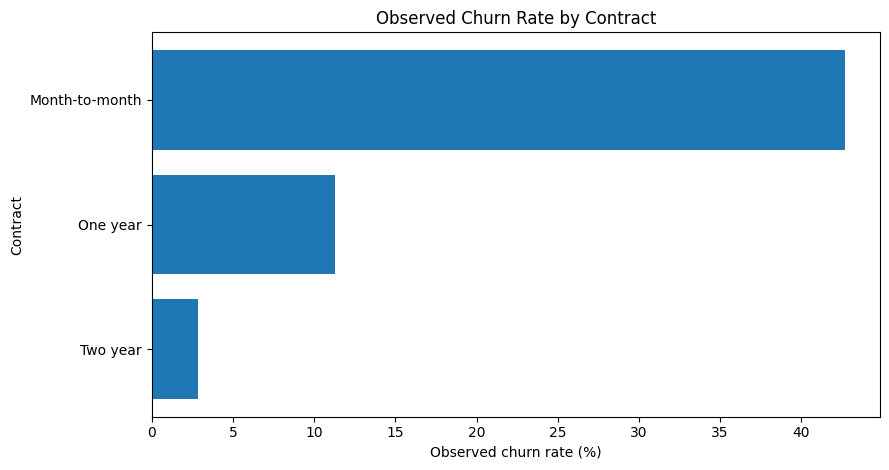

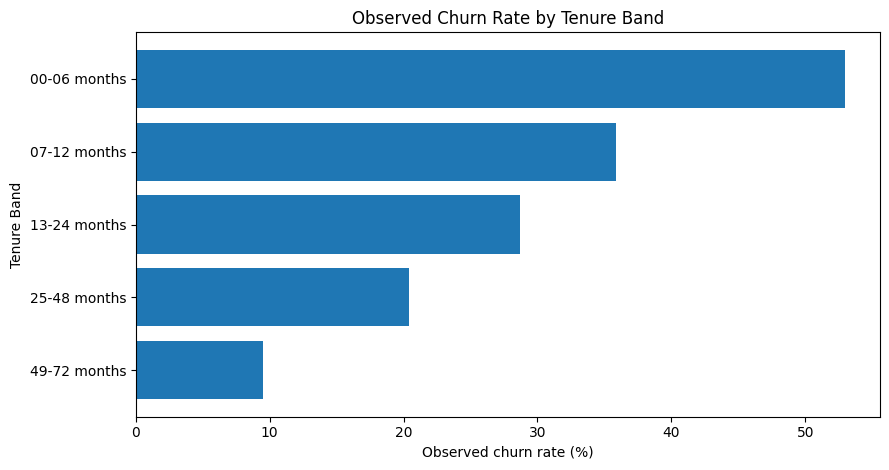

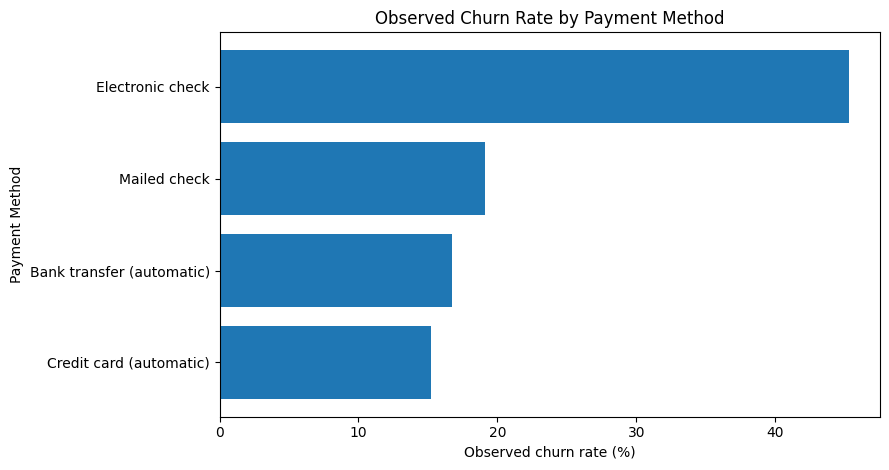

In [7]:
# Charts are generated from the downloaded data only after prior cells run.
for column in ["contract", "tenure_band", "payment_method"]:
    if column not in segment_outputs:
        continue
    plot_data = segment_outputs[column].dropna(subset=["churn_rate_pct"]).sort_values("churn_rate_pct")
    if plot_data.empty:
        continue
    plt.figure(figsize=(9, 4.8))
    plt.barh(plot_data[column].astype(str), plot_data["churn_rate_pct"])
    plt.xlabel("Observed churn rate (%)")
    plt.ylabel(column.replace("_", " ").title())
    plt.title(f"Observed Churn Rate by {column.replace('_', ' ').title()}")
    plt.tight_layout()
    plt.show()

## 3b. Cleaning decision log (investigate blank `total_charges` before deciding)

In [8]:
# CLEANING_DECISION_LOG
blank_tc = df[df["total_charges"].isna()]
print("Rows with blank TotalCharges:", len(blank_tc))
display(blank_tc[["customer_id", "tenure", "monthly_charges", "contract", "churn"]])
print("tenure values among blank rows:", sorted(blank_tc["tenure"].unique().tolist()))
print("churn labels among blank rows:", blank_tc["churn"].value_counts().to_dict())
print("Rows with tenure == 0 overall:", int((df["tenure"] == 0).sum()))

decision_log = pd.DataFrame([
    {"issue": "Duplicate customer IDs", "actual_count": int(duplicate_customer_ids),
     "decision": "No action needed", "rationale": "customer_id is unique; no row dropped."},
    {"issue": "Blank TotalCharges", "actual_count": int(len(blank_tc)),
     "decision": "Keep rows; leave total_charges as missing (no imputation)",
     "rationale": "All blank rows have tenure = 0 (new customers not yet billed). Churn label is valid, so they stay in churn KPIs. total_charges is not used in any KPI."},
    {"issue": "Invalid churn categories", "actual_count": int((~df["churn"].isin(["Yes", "No"])).sum()),
     "decision": "No action needed", "rationale": "Only Yes/No present."},
    {"issue": "Invalid tenure / charge values",
     "actual_count": int(((df["tenure"] < 0) | (df["tenure"] > 72) | (df["monthly_charges"] <= 0)).sum()),
     "decision": "No action needed", "rationale": "tenure within 0-72, monthly_charges > 0."},
])
display(decision_log)
decision_log.to_csv(OUTPUT_DIR / "cleaning_decision_log.csv", index=False)

Rows with blank TotalCharges: 11


,customer_id,tenure,monthly_charges,contract,churn
488,4472-LVYGI,0,52.55,Two year,No
753,3115-CZMZD,0,20.25,Two year,No
936,5709-LVOEQ,0,80.85,Two year,No
1082,4367-NUYAO,0,25.75,Two year,No
1340,1371-DWPAZ,0,56.05,Two year,No
3331,7644-OMVMY,0,19.85,Two year,No
3826,3213-VVOLG,0,25.35,Two year,No
4380,2520-SGTTA,0,20.00,Two year,No
5218,2923-ARZLG,0,19.70,One year,No
6670,4075-WKNIU,0,73.35,Two year,No


tenure values among blank rows: [0]
churn labels among blank rows: {'No': 11}
Rows with tenure == 0 overall: 11


,issue,actual_count,decision,rationale
0,Duplicate customer IDs,0,No action needed,customer_id is unique; no row dropped.
1,Blank TotalCharges,11,Keep rows; leave total_charges as missing (no ...,All blank rows have tenure = 0 (new customers ...
2,Invalid churn categories,0,No action needed,Only Yes/No present.
3,Invalid tenure / charge values,0,No action needed,"tenure within 0-72, monthly_charges > 0."


## 4b. Export the cleaned customer table (processed data, raw file stays untouched)

In [9]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

clean = analysis.copy()
clean["tenure_band"] = clean["tenure_band"].astype(str)
clean["senior_citizen_label"] = clean["senior_citizen"].map({1: "Yes", 0: "No"})
clean.to_csv(PROCESSED_DIR / "telco_customer_churn_clean.csv", index=False)
print("Saved:", PROCESSED_DIR / "telco_customer_churn_clean.csv", clean.shape)

# Internal reconciliation (replaces the SQL-vs-Python check because no database is used)
assert len(clean) == len(raw), "Rows were dropped unexpectedly"
assert clean["customer_id"].is_unique
assert clean["churn_flag"].sum() == (clean["churn"] == "Yes").sum()
print("Reconciliation OK: raw rows =", len(raw), "| clean rows =", len(clean), "| excluded = 0")

Saved: C:\Users\ARII\Documents\proyek data analis\customer_churn_retention_analytics\data\processed\telco_customer_churn_clean.csv (7043, 24)
Reconciliation OK: raw rows = 7043 | clean rows = 7043 | excluded = 0


## 5b. More segments, churned-customer share, and lift vs. overall baseline

In [10]:
overall_rate = 100 * analysis["churn_flag"].mean()
total_churned = int(analysis["churn_flag"].sum())

extra_segment_columns = ["senior_citizen_label", "partner", "dependents", "gender",
                         "multiple_lines", "online_backup", "device_protection",
                         "streaming_tv", "streaming_movies", "phone_service"]
all_segment_columns = ["contract", "tenure_band", "payment_method", "internet_service",
                       "tech_support", "online_security", "paperless_billing"] + extra_segment_columns

seg_frame = clean.copy()
rows = []
for col in all_segment_columns:
    s = segment_summary(seg_frame, col).rename(columns={col: "segment_value"})
    s.insert(0, "dimension", col)
    s["segment_value"] = s["segment_value"].astype(str)
    s["share_of_all_churned_pct"] = (100 * s["churned_customers"] / total_churned).round(2)
    s["lift_vs_overall"] = (s["churn_rate_pct"] / overall_rate).round(2)
    rows.append(s)
segments_long = pd.concat(rows, ignore_index=True)
segments_long.to_csv(OUTPUT_DIR / "segments_all.csv", index=False)
print(f"Overall churn rate baseline: {overall_rate:.2f}% | total churned: {total_churned}")
display(segments_long[segments_long["dimension"].isin(extra_segment_columns)])

Overall churn rate baseline: 26.54% | total churned: 1869


,dimension,segment_value,customers,churned_customers,churn_rate_pct,share_of_all_churned_pct,lift_vs_overall
23,senior_citizen_label,Yes,1142,476,41.68,25.47,1.57
24,senior_citizen_label,No,5901,1393,23.61,74.53,0.89
25,partner,No,3641,1200,32.96,64.21,1.24
26,partner,Yes,3402,669,19.66,35.79,0.74
27,dependents,No,4933,1543,31.28,82.56,1.18
28,dependents,Yes,2110,326,15.45,17.44,0.58
29,gender,Female,3488,939,26.92,50.24,1.01
30,gender,Male,3555,930,26.16,49.76,0.99
31,multiple_lines,Yes,2971,850,28.61,45.48,1.08
32,multiple_lines,No,3390,849,25.04,45.43,0.94


## 6b. Prioritization: rate + volume, with a minimum-size threshold and a sensitivity test

Segments are ranked by observed churn rate **after** removing segments smaller than a minimum size. The threshold is a documented analyst choice; the table below shows whether the ranking changes when it changes. Ranking is descriptive, not a causal risk score.

In [11]:
def ranked(min_size, top=8):
    t = segments_long[segments_long["customers"] >= min_size]
    t = t.sort_values(["churn_rate_pct", "customers"], ascending=[False, False]).head(top)
    return t[["dimension", "segment_value", "customers", "churned_customers",
              "churn_rate_pct", "share_of_all_churned_pct", "lift_vs_overall"]]

MIN_SIZE = 300  # chosen: ~4% of customers; avoids tiny segments dominating
priority = ranked(MIN_SIZE)
display(priority)
priority.to_csv(OUTPUT_DIR / "segment_priority.csv", index=False)

# Sensitivity: does the top-5 change with the threshold?
sens = []
for m in [100, 300, 500, 1000]:
    top5 = ranked(m, 5)
    sens.append({"min_size": m, "top5": " | ".join(f"{d}={v}" for d, v in zip(top5["dimension"], top5["segment_value"]))})
sens = pd.DataFrame(sens)
pd.set_option("display.max_colwidth", 200)
display(sens)
sens.to_csv(OUTPUT_DIR / "segment_priority_sensitivity.csv", index=False)

,dimension,segment_value,customers,churned_customers,churn_rate_pct,share_of_all_churned_pct,lift_vs_overall
3,tenure_band,00-06 months,1481,784,52.94,41.95,1.99
8,payment_method,Electronic check,2365,1071,45.29,57.30,1.71
0,contract,Month-to-month,3875,1655,42.71,88.55,1.61
12,internet_service,Fiber optic,3096,1297,41.89,69.40,1.58
18,online_security,No,3498,1461,41.77,78.17,1.57
23,senior_citizen_label,Yes,1142,476,41.68,25.47,1.57
15,tech_support,No,3473,1446,41.64,77.37,1.57
34,online_backup,No,3088,1233,39.93,65.97,1.50


,min_size,top5
0,100,tenure_band=00-06 months | payment_method=Electronic check | contract=Month-to-month | internet_service=Fiber optic | online_security=No
1,300,tenure_band=00-06 months | payment_method=Electronic check | contract=Month-to-month | internet_service=Fiber optic | online_security=No
2,500,tenure_band=00-06 months | payment_method=Electronic check | contract=Month-to-month | internet_service=Fiber optic | online_security=No
3,1000,tenure_band=00-06 months | payment_method=Electronic check | contract=Month-to-month | internet_service=Fiber optic | online_security=No


## 6c. Contract x tenure (checks whether tenure and contract effects overlap)

In [12]:
ct = (clean.groupby(["contract", "tenure_band"], observed=True)
      .agg(customers=("customer_id", "nunique"), churned_customers=("churn_flag", "sum"))
      .reset_index())
ct["churn_rate_pct"] = (100 * ct["churned_customers"] / ct["customers"]).round(2)
display(ct.pivot(index="tenure_band", columns="contract", values="churn_rate_pct"))
display(ct.pivot(index="tenure_band", columns="contract", values="customers"))
ct.to_csv(OUTPUT_DIR / "churn_by_contract_x_tenure.csv", index=False)

# Internet service x tech support (add-on effect within the same internet type)
it = (clean[clean["internet_service"] != "No"]
      .groupby(["internet_service", "tech_support"])
      .agg(customers=("customer_id", "nunique"), churned_customers=("churn_flag", "sum"))
      .reset_index())
it["churn_rate_pct"] = (100 * it["churned_customers"] / it["customers"]).round(2)
display(it)
it.to_csv(OUTPUT_DIR / "churn_by_internet_x_techsupport.csv", index=False)

contract,Month-to-month,One year,Two year
tenure_band,,,
00-06 months,55.20,10.26,0.00
07-12 months,42.00,10.59,0.00
13-24 months,37.72,8.12,0.00
25-48 months,32.92,10.62,2.19
49-72 months,26.02,12.93,3.33


contract,Month-to-month,One year,Two year
tenure_band,,,
00-06 months,1413,39,29
07-12 months,581,85,39
13-24 months,737,197,90
25-48 months,802,518,274
49-72 months,342,634,1263


,internet_service,tech_support,customers,churned_customers,churn_rate_pct
0,DSL,No,1243,345,27.76
1,DSL,Yes,1178,114,9.68
2,Fiber optic,No,2230,1101,49.37
3,Fiber optic,Yes,866,196,22.63


## 6d. Billing profile and saved figures

In [13]:
billing = (clean.groupby("churn")
           .agg(customers=("customer_id", "nunique"),
                avg_tenure_months=("tenure", "mean"),
                median_tenure_months=("tenure", "median"),
                avg_monthly_charges=("monthly_charges", "mean"),
                median_monthly_charges=("monthly_charges", "median"),
                sum_monthly_charges=("monthly_charges", "sum"))
           .round(2).reset_index())
display(billing)
billing.to_csv(OUTPUT_DIR / "billing_profile_by_churn.csv", index=False)

FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
for column in ["contract", "tenure_band", "payment_method", "internet_service"]:
    pdta = segment_summary(seg_frame, column).sort_values("churn_rate_pct")
    fig, ax = plt.subplots(figsize=(9, 4.5))
    bars = ax.barh(pdta[column].astype(str), pdta["churn_rate_pct"], color="#2a6f97")
    ax.axvline(overall_rate, color="#c1121f", linestyle="--", label=f"Overall {overall_rate:.1f}%")
    for bar, n, c in zip(bars, pdta["customers"], pdta["churned_customers"]):
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, f"n={n:,} (churned {c:,})", va="center", fontsize=8)
    ax.set_xlabel("Observed churn rate (%)")
    ax.set_title(f"Observed churn rate by {column.replace('_', ' ')}")
    ax.set_xlim(0, pdta["churn_rate_pct"].max() * 1.35)
    ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"churn_by_{column}.png", dpi=130)
    plt.close(fig)
print("Figures saved to", FIG_DIR)

,churn,customers,avg_tenure_months,median_tenure_months,avg_monthly_charges,median_monthly_charges,sum_monthly_charges
0,No,5174,37.57,38.0,61.27,64.43,316985.75
1,Yes,1869,17.98,10.0,74.44,79.65,139130.85


Figures saved to C:\Users\ARII\Documents\proyek data analis\customer_churn_retention_analytics\outputs\figures


## 7. Findings checklist (complete only after inspecting outputs)

For each finding, record:

- segment definition and sample size;
- churned-customer count and churn rate;
- comparison group and overall baseline;
- whether the pattern remains when considering segment volume;
- possible alternative explanations;
- proposed business action framed as a testable hypothesis.

Do **not** treat correlation as causation. This dataset does not provide enough dated longitudinal history for true cohort analysis or backtesting a future-period churn forecast.